# QAP10 · Track B: recarga de flotas eléctricas
**NTT DATA – IBM Quantum Hackathon 2026.** Este notebook recorre el proyecto paso a paso. Cada celda usa los módulos del repositorio (`data.py`, `classical.py`, `qiskit_qaoa.py`, `experiments.py`, `plots.py`).

> Idea en una frase: **tenemos 10 rutas eléctricas y 10 estaciones de recarga; queremos que las rutas que más se relacionan entre sí queden en estaciones cercanas.** Comparamos un método clásico con uno cuántico (QAOA en Qiskit).

Las celdas pesadas (QAOA para N=10, ~30 min) no se vuelven a correr aquí: se leen de `results/`. Una pequeña demo de QAOA sí corre en vivo (~5 s).

In [1]:
import json, time, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
from IPython.display import Image, Markdown, display
import numpy as np

import data, classical, qiskit_qaoa as qq, plots
RESULTS = Path("results")

## 1. Los datos: de dónde salen F y D
El archivo `qap10.mps.gz` (MIPLIB) no trae las matrices: trae **las multiplicaciones ya hechas** (F_ik·D_jl) en 4050 variables. Como para cada par de rutas la tabla de coeficientes es siempre *la misma tabla D multiplicada por un número* (F_ik), podemos separar los dos factores. Fijamos la escala con D entera (resulta ser una distancia de cuadrícula).

In [2]:
F, D, coef = data.load_qap()
print("F (flujo entre rutas):"); print(F)
print("\nD (distancia entre estaciones):"); print(D)

F (flujo entre rutas):
[[ 0 10  4  8  2  0  0 12  4  2]
 [10  0  6  0  4  4  4  0  8 10]
 [ 4  6  0  0  0  0  0 10 10  4]
 [ 8  0  0  0 10  4  4 20  0  0]
 [ 2  4  0 10  0 20  0  0  0 10]
 [ 0  4  0  4 20  0 10  2  2 10]
 [ 0  4  0  4  0 10  0 20 10  4]
 [12  0 10 20  0  2 20  0  0  0]
 [ 4  8 10  0  0  2 10  0  0  0]
 [ 2 10  4  0 10 10  4  0  0  0]]

D (distancia entre estaciones):
[[0 1 2 3 1 2 3 4 2 3]
 [1 0 1 2 2 1 2 3 3 2]
 [2 1 0 1 3 2 1 2 4 3]
 [3 2 1 0 4 3 2 1 5 4]
 [1 2 3 4 0 1 2 3 1 2]
 [2 1 2 3 1 0 1 2 2 1]
 [3 2 1 2 2 1 0 1 3 2]
 [4 3 2 1 3 2 1 0 4 3]
 [2 3 4 5 1 2 3 4 0 1]
 [3 2 3 4 2 1 2 3 1 0]]


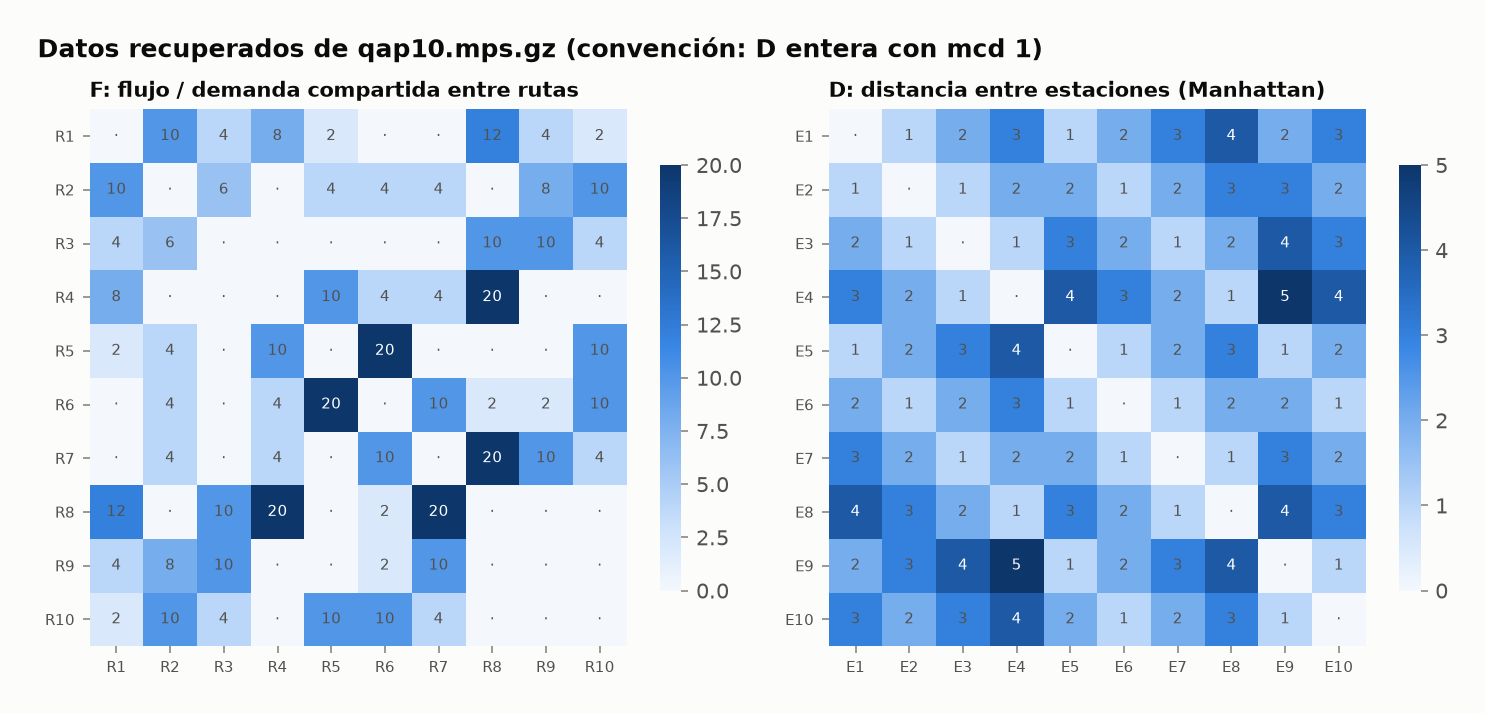

In [3]:
display(Image(plots.fig_matrices()))

### Validación: el costo coincide con el archivo y con los óptimos de control
Costo de una asignación π (cada par una sola vez): **C(π) = Σ_{i<k} F_ik · D_{π(i)π(k)}**.

In [4]:
rng = np.random.default_rng(0)
ok = all(data.qap_cost(p, F, D) == data.mps_objective(p, coef)
         for p in (rng.permutation(10).tolist() for _ in range(200)))
print("qap_cost == objetivo del MPS en 200 permutaciones:", ok)
for N in (3, 4):
    r = classical.brute_force(*data.subinstance(F, D, N))
    print(f"N={N}: óptimo {r['cost']} (esperado {data.CONTROLS[N]}) en {r['time_s']*1000:.2f} ms")

qap_cost == objetivo del MPS en 200 permutaciones: True
N=3: óptimo 24 (esperado 24) en 0.00 ms
N=4: óptimo 32 (esperado 32) en 0.00 ms


## 2. Baseline clásico
**Fuerza bruta** = probar todas las asignaciones. Para N=10 son 10! = 3.628.800; se recorren una a una (sin guardarlas). Aquí leemos el resultado guardado (tarda ~7 s).

In [5]:
brute = json.loads((RESULTS / "classical_bruteforce.json").read_text(encoding="utf-8"))
for r in brute:
    print(f"N={r['N']:2d}: costo {r['cost']}  ({r['n_evaluated']:,} permutaciones, {r['time_s']} s)  "
          f"asignación: {classical.format_assignment(r['perm'])}")

N= 3: costo 24  (6 permutaciones, 0.0 s)  asignación: R1->E1, R2->E2, R3->E3
N= 4: costo 32  (24 permutaciones, 0.0 s)  asignación: R1->E2, R2->E3, R3->E4, R4->E1
N=10: costo 340  (3,628,800 permutaciones, 7.0926 s)  asignación: R1->E3, R2->E7, R3->E4, R4->E1, R5->E9, R6->E5, R7->E6, R8->E2, R9->E8, R10->E10


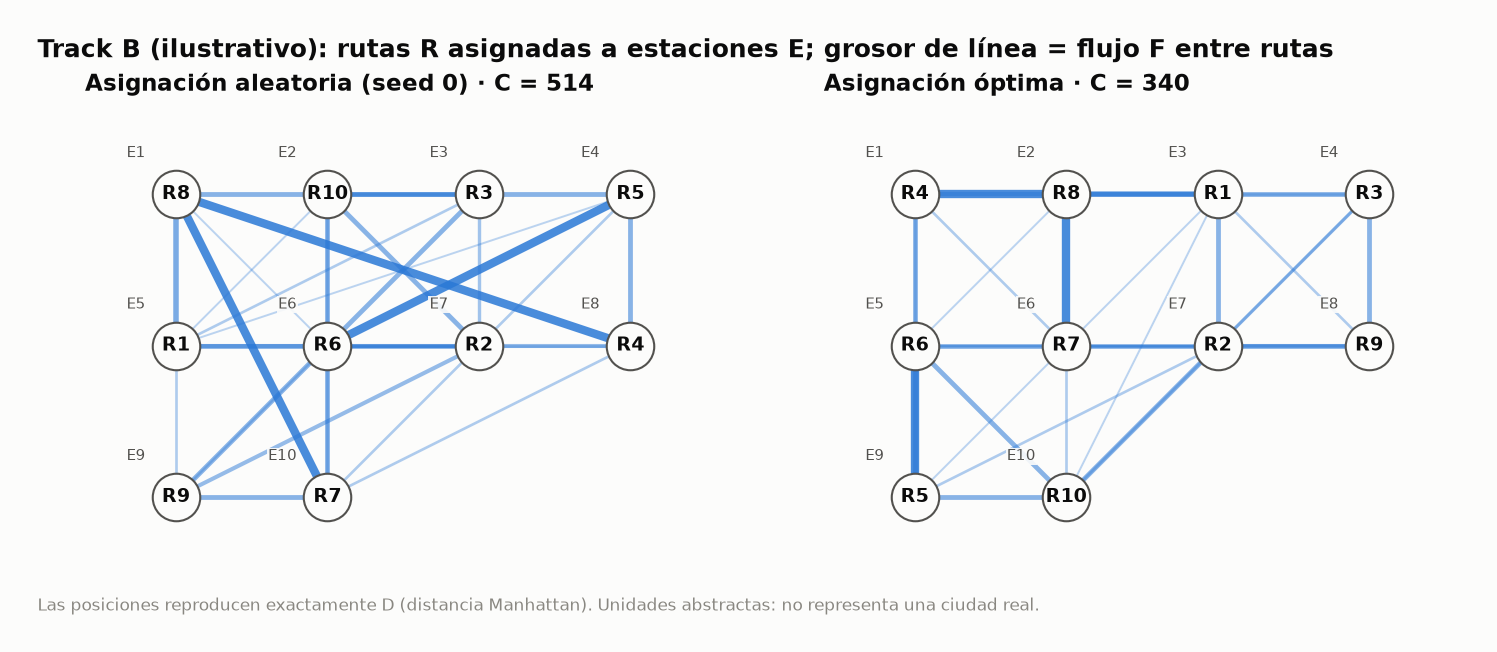

In [6]:
display(Image(plots.fig_layout()))

## 3. El camino cuántico: QUBO → Ising → QAOA
1. **Variables sí/no:** x_ij = 1 si la ruta i va a la estación j → N² qubits.
2. **Reglas como multas (QUBO):** a cada regla rota (“una ruta sin estación”, “dos rutas en la misma estación”) le sumamos una multa λ. La multa debe ser **mayor que lo que se ahorra haciendo trampa** (Δ).
3. **Ising:** reescribimos el QUBO como un Hamiltoniano de qubits (`SparsePauliOp`).
4. **QAOA:** un circuito con perillas (γ, β). Un optimizador clásico gira las perillas para que, al medir, salgan con más probabilidad las asignaciones baratas.

### Demo en vivo (N=3, 9 qubits, p=1)

In [7]:
F3, D3 = data.subinstance(F, D, 3)
qp = qq.build_quadratic_program(F3, D3)
delta = qq.penalty_bound(F3, D3)
qubo, op, offset = qq.to_qubo_ising(qp, lam=delta)
print(f"Variables: {qp.get_num_vars()} · restricciones: {qp.get_num_linear_constraints()} · Δ = λ = {delta}")
print(f"Hamiltoniano de Ising: {op.num_qubits} qubits, {len(op)} términos Pauli, offset {offset:g}")
print(op[:6], "...")

Variables: 9 · restricciones: 6 · Δ = λ = 32
Hamiltoniano de Ising: 9 qubits, 45 términos Pauli, offset 232
SparsePauliOp(['IIIIIIIIZ', 'IIIIIIIZI', 'IIIIIIZII', 'IIIIIZIII', 'IIIIZIIII', 'IIIZIIIII'],
              coeffs=[-42.5+0.j, -39. +0.j, -42.5+0.j, -44. +0.j, -40. +0.j, -44. +0.j]) ...


In [8]:
t0 = time.perf_counter()
res = qq.run_qaoa(op, reps=1)
m = qq.evaluate_samples(res["counts"], qubo, F3, D3)
print(f"Tiempo: {time.perf_counter()-t0:.1f} s · evaluaciones del circuito: {res['n_energy_evals']}")
print(f"Muestras factibles: {m['feasible_fraction']:.1%} (azar: {6/512:.1%}) · óptimas: {m['optimal_fraction']:.1%}")
print(f"Mejor costo factible: {m['best_feasible_cost']} (óptimo 24) · energía QUBO mínima: {m['min_qubo_energy']:g}")

Tiempo: 1.3 s · evaluaciones del circuito: 123
Muestras factibles: 9.0% (azar: 1.2%) · óptimas: 3.5%
Mejor costo factible: 24 (óptimo 24) · energía QUBO mínima: 24


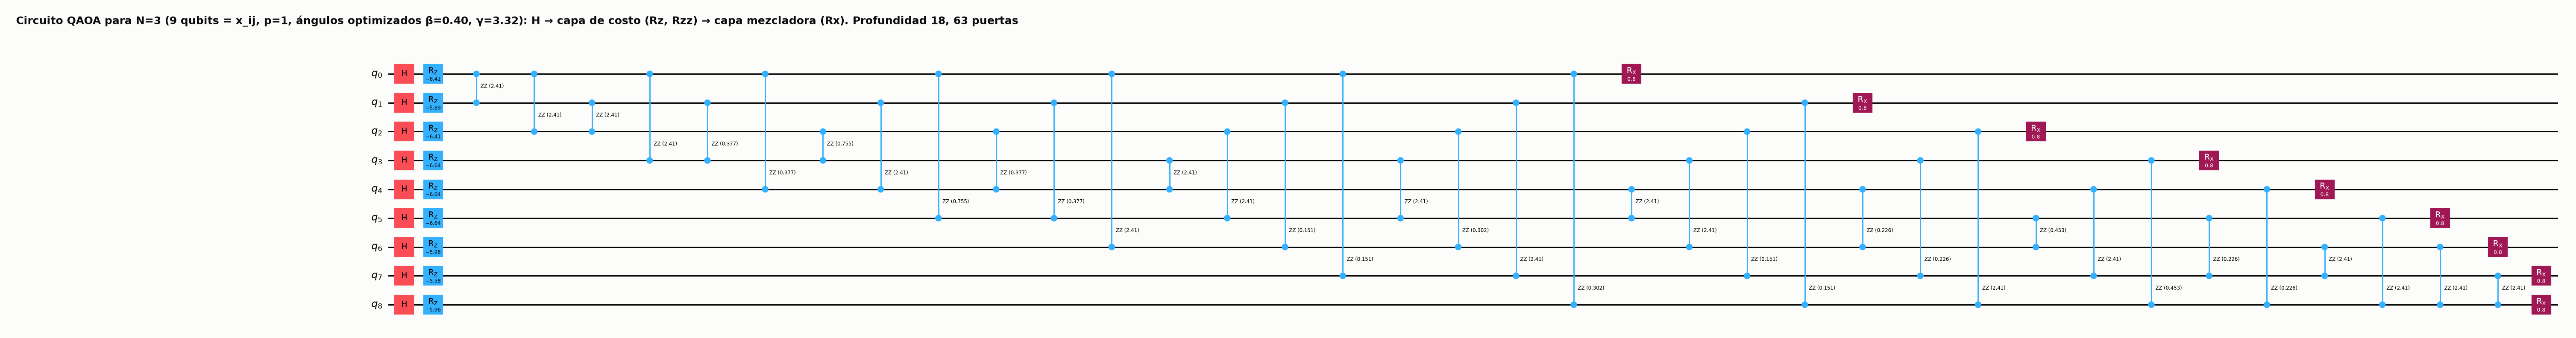

In [9]:
display(Image(plots.fig_circuit()))

## 4. Resultados N=3 y N=4
### Histogramas de probabilidad
Azul = asignación óptima, naranja = válida pero no óptima, gris = rompe alguna regla.

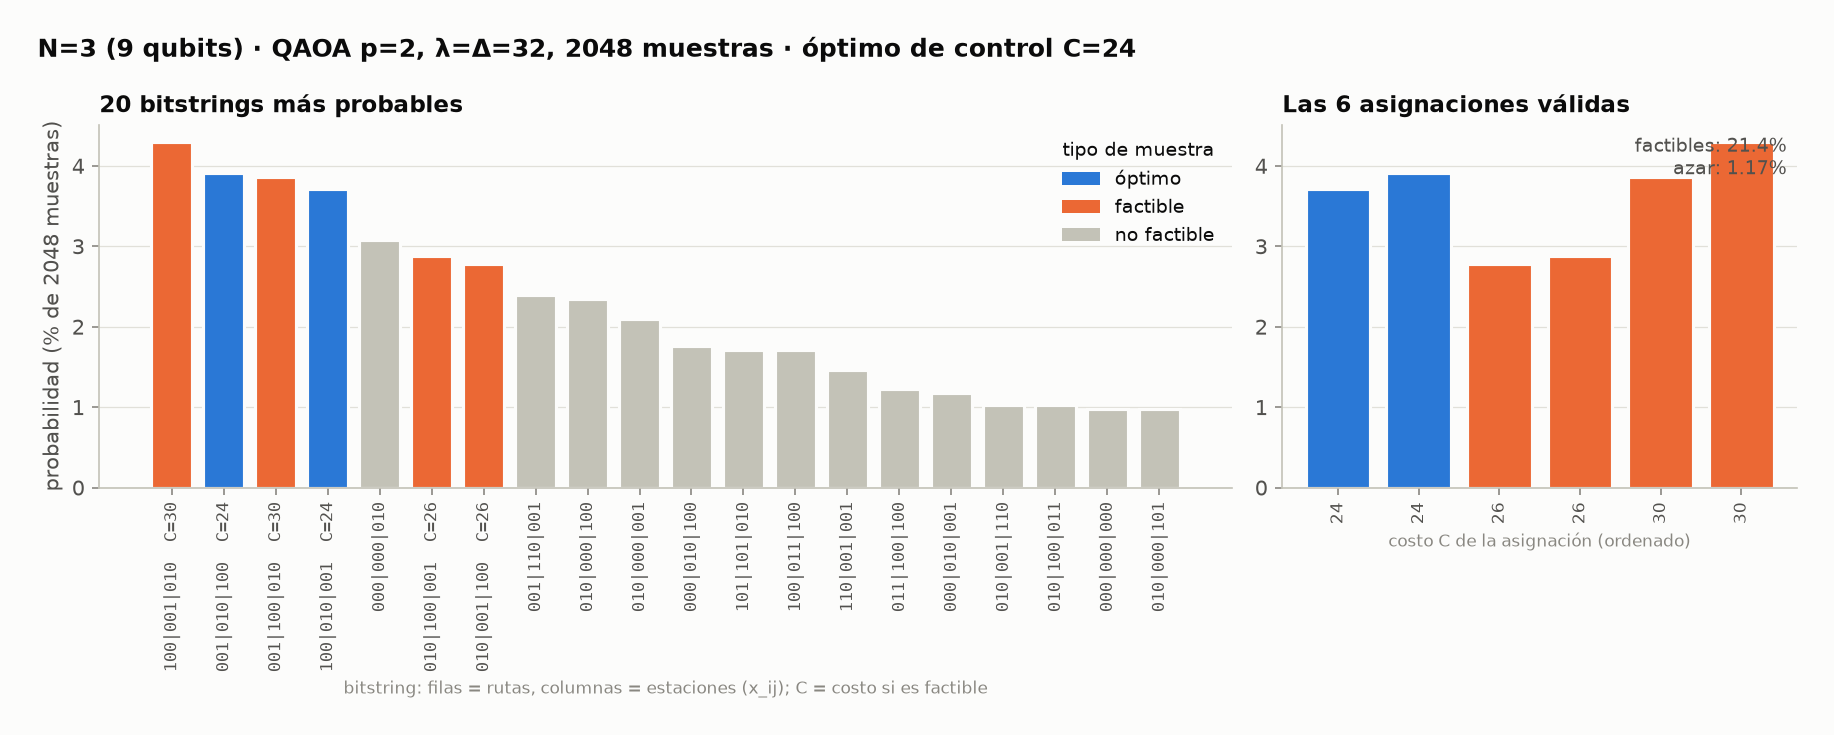

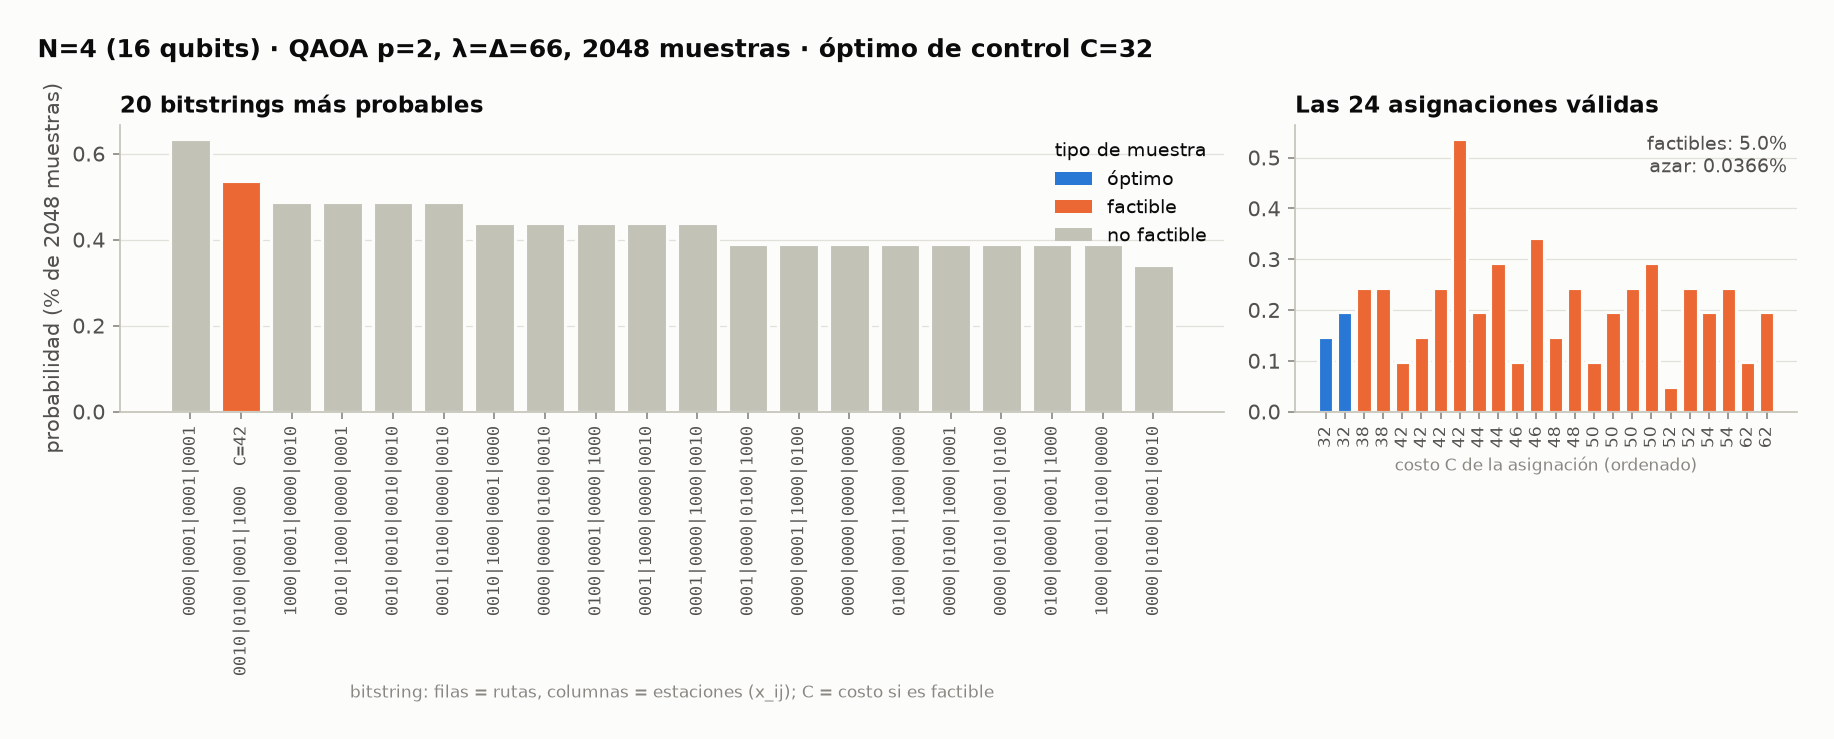

In [10]:
display(Image(plots.fig_histogram(3)))
display(Image(plots.fig_histogram(4)))

### ¿Qué λ y qué profundidad p funcionan mejor?
Con λ demasiado pequeño, QAOA puede ser *peor que el azar*: la energía más baja corresponde a una asignación inválida.

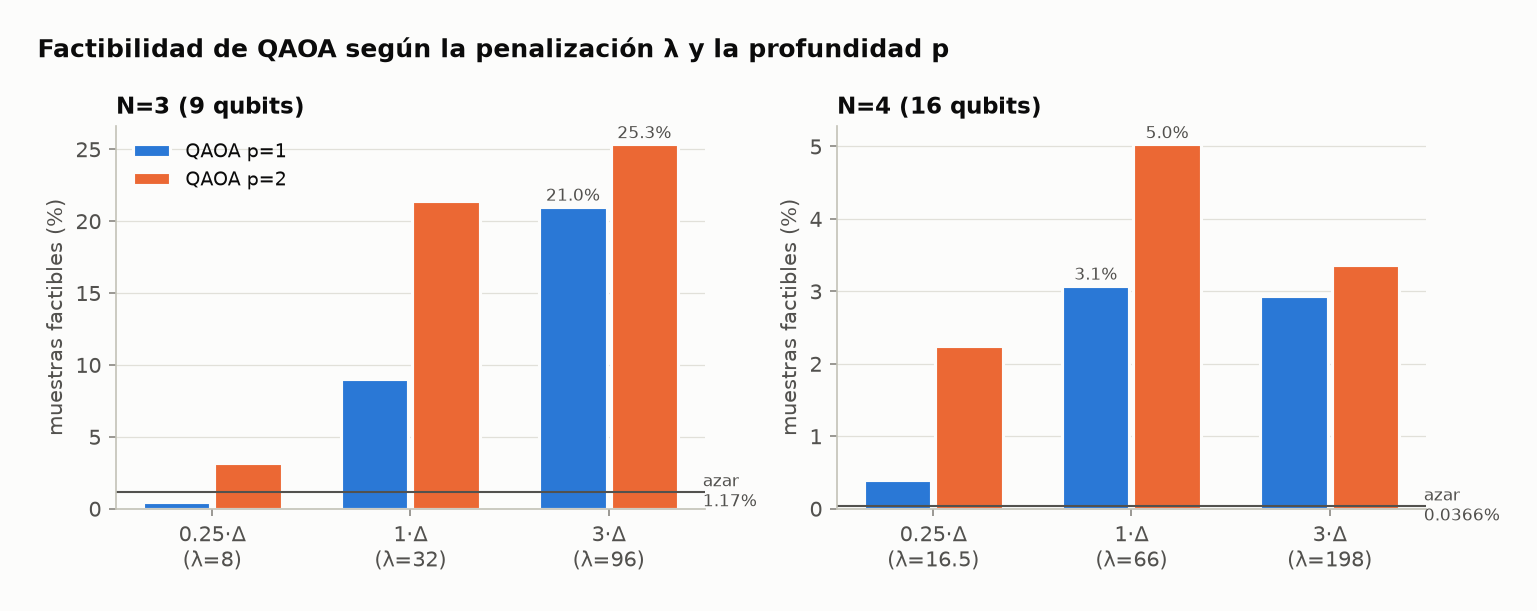

In [11]:
display(Image(plots.fig_feasibility()))

### Energía QUBO ≠ costo
La energía incluye las multas; el costo solo existe para asignaciones válidas. QAOA mueve las muestras hacia energías bajas.

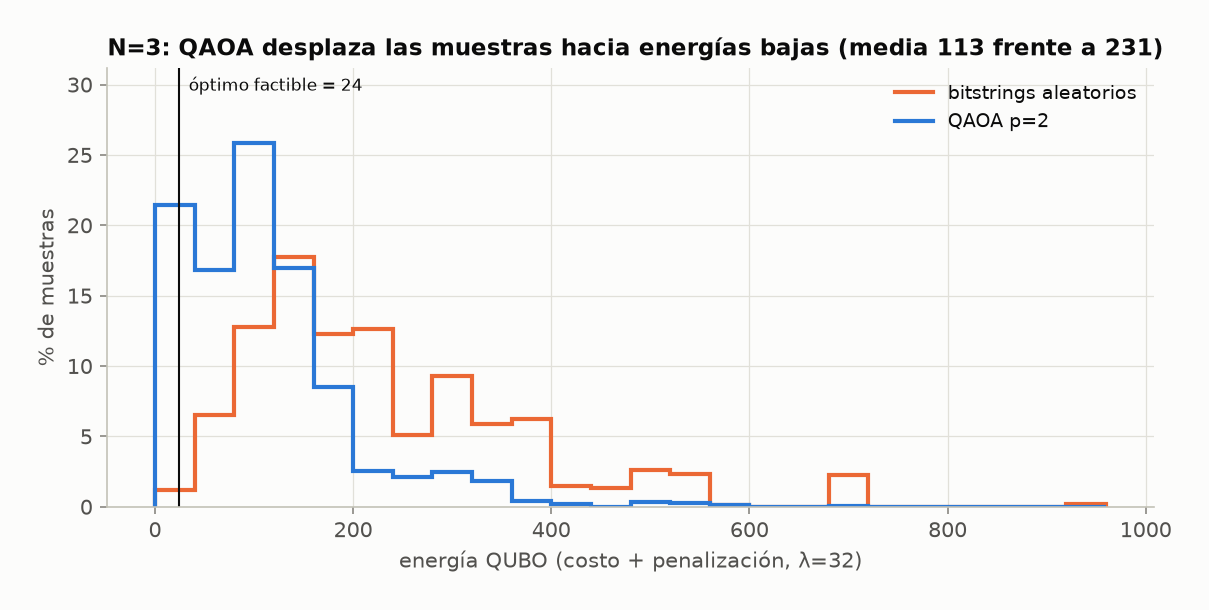

In [12]:
display(Image(plots.fig_energy(3)))

In [13]:
display(Markdown((RESULTS / "comparison_N3_N4.md").read_text(encoding="utf-8")))

| N | metodo | lambda | p | muestras | pct_factibles | pct_optimas | mejor_costo_factible | gap_pct | E_qubo_min | E_qubo_media | tiempo_s | nota |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 3 | clasico_fuerza_bruta |  |  | 6 | 100.0 | 33.33 | 24 | 0.0 |  |  | 0.0 | exacto, enumera N! permutaciones |
| 3 | aleatorio_bits | 8.0 |  | 2048 | 1.17 | 0.29 | 24 | 0.0 | 20.0 | 87.6 | 0.234 | teórico: 1.17% fact., 0.391% ópt. |
| 3 | qiskit_qaoa | 8.0 | 1 | 2048 | 0.49 | 0.2 | 24 | 0.0 | 20.0 | 47.6 | 1.743 | 0.25*Delta; mínimo QUBO NO factible |
| 3 | qiskit_qaoa | 8.0 | 2 | 2048 | 3.17 | 1.32 | 24 | 0.0 | 20.0 | 32.0 | 9.284 | 0.25*Delta; mínimo QUBO NO factible |
| 3 | aleatorio_bits | 32.0 |  | 2048 | 0.83 | 0.2 | 24 | 0.0 | 24.0 | 235.1 | 0.601 | teórico: 1.17% fact., 0.391% ópt. |
| 3 | qiskit_qaoa | 32.0 | 1 | 2048 | 9.03 | 3.47 | 24 | 0.0 | 24.0 | 173.4 | 1.741 | 1.0*Delta; mínimo QUBO factible |
| 3 | qiskit_qaoa | 32.0 | 2 | 2048 | 21.44 | 7.62 | 24 | 0.0 | 24.0 | 113.4 | 8.308 | 1.0*Delta; mínimo QUBO factible |
| 3 | aleatorio_bits | 96.0 |  | 2048 | 1.07 | 0.29 | 24 | 0.0 | 24.0 | 615.1 | 0.545 | teórico: 1.17% fact., 0.391% ópt. |
| 3 | qiskit_qaoa | 96.0 | 1 | 2048 | 21.0 | 6.54 | 24 | 0.0 | 24.0 | 241.6 | 1.828 | 3.0*Delta; mínimo QUBO factible |
| 3 | qiskit_qaoa | 96.0 | 2 | 2048 | 25.34 | 7.91 | 24 | 0.0 | 24.0 | 214.4 | 6.662 | 3.0*Delta; mínimo QUBO factible |
| 3 | aleatorio_perm |  |  | 2048 | 100.0 | 34.13 | 24 | 0.0 | 24.0 | 26.7 | 0.047 | búsqueda aleatoria clásica; E_qubo = costo (sin penalización) |
| 4 | clasico_fuerza_bruta |  |  | 24 | 100.0 | 8.33 | 32 | 0.0 |  |  | 0.0 | exacto, enumera N! permutaciones |
| 4 | aleatorio_bits | 16.5 |  | 2048 | 0.1 | 0.0 | 52 | 62.5 | 39.0 | 408.0 | 2.0 | teórico: 0.0366% fact., 0.00305% ópt. |
| 4 | qiskit_qaoa | 16.5 | 1 | 2048 | 0.39 | 0.1 | 32 | 0.0 | 32.0 | 124.9 | 7.461 | 0.25*Delta; mínimo QUBO factible |
| 4 | qiskit_qaoa | 16.5 | 2 | 2048 | 2.25 | 0.39 | 32 | 0.0 | 32.0 | 83.1 | 38.287 | 0.25*Delta; mínimo QUBO factible |
| 4 | aleatorio_bits | 66.0 |  | 2048 | 0.0 | 0.0 |  |  | 138.0 | 1214.5 | 1.838 | teórico: 0.0366% fact., 0.00305% ópt. |
| 4 | qiskit_qaoa | 66.0 | 1 | 2048 | 3.08 | 0.24 | 32 | 0.0 | 32.0 | 461.1 | 7.652 | 1.0*Delta; mínimo QUBO factible |
| 4 | qiskit_qaoa | 66.0 | 2 | 2048 | 5.03 | 0.34 | 32 | 0.0 | 32.0 | 427.3 | 25.387 | 1.0*Delta; mínimo QUBO factible |
| 4 | aleatorio_bits | 198.0 |  | 2048 | 0.0 | 0.0 |  |  | 402.0 | 3283.6 | 1.879 | teórico: 0.0366% fact., 0.00305% ópt. |
| 4 | qiskit_qaoa | 198.0 | 1 | 2048 | 2.93 | 0.29 | 32 | 0.0 | 32.0 | 766.5 | 8.648 | 3.0*Delta; mínimo QUBO factible |
| 4 | qiskit_qaoa | 198.0 | 2 | 2048 | 3.37 | 0.2 | 32 | 0.0 | 32.0 | 762.4 | 30.336 | 3.0*Delta; mínimo QUBO factible |
| 4 | aleatorio_perm |  |  | 2048 | 100.0 | 8.4 | 32 | 0.0 | 32.0 | 46.5 | 0.083 | búsqueda aleatoria clásica; E_qubo = costo (sin penalización) |


## 5. Instancia completa N=10 (híbrido)
100 qubits no caben en un simulador (2¹⁰⁰ amplitudes). Por eso **congelamos 7 rutas y dejamos libres 3 (9 qubits) o 4 (16 qubits)**; QAOA reorganiza las libres y repetimos. Comparamos contra el mismo procedimiento con un subsolver clásico exacto y contra búsqueda local clásica.

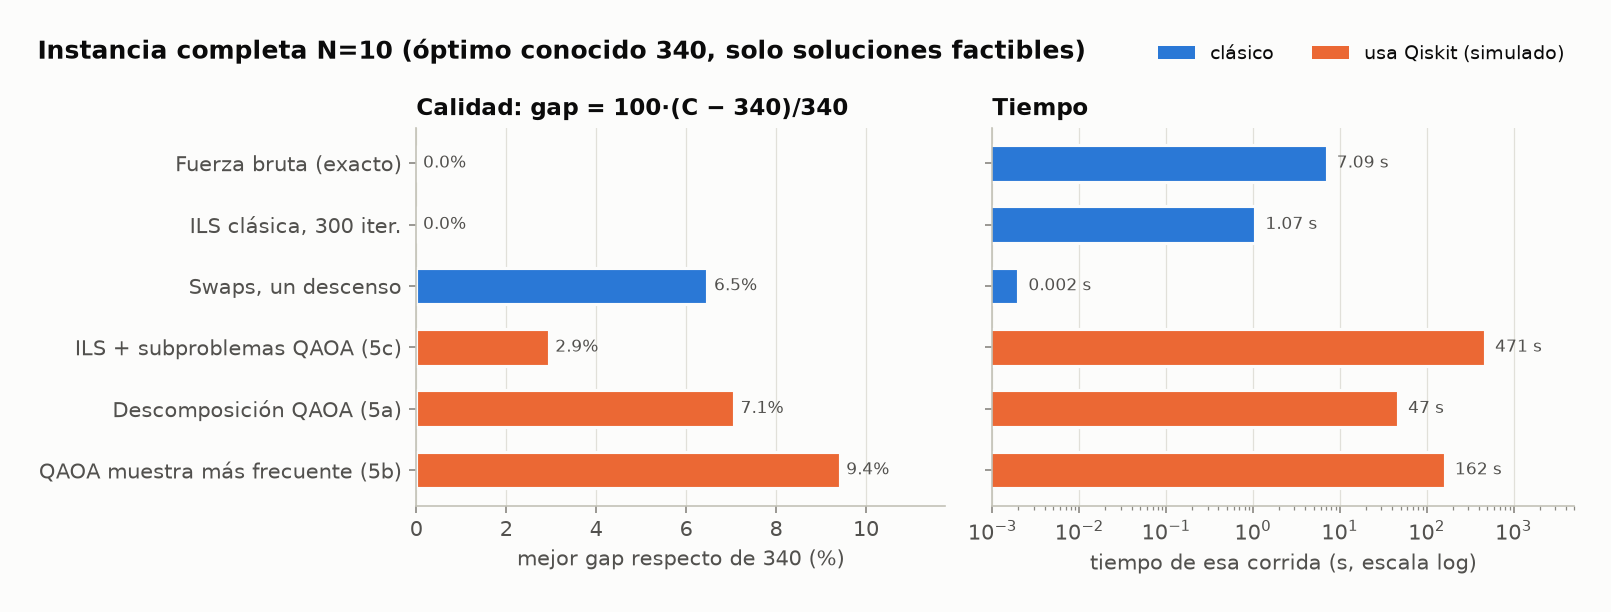

In [14]:
display(Image(plots.fig_n10()))

In [15]:
for name in ("n10_hybrid", "n10_top", "n10_ils", "n10_ils_long"):
    display(Markdown(f"#### {name}\n" + (RESULTS / f"{name}.md").read_text(encoding="utf-8")))

#### n10_hybrid
| metodo | seed | m | subproblems | C_inicial | C_tras_subproblemas | gap_tras_subproblemas | C_final_tras_swaps | gap_final | aceptados | reparados | pct_factibles_medio | tiempo_subproblemas_s | tiempo_pulido_s |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| clasico_swaps | 0 |  |  | 514 |  |  | 362 | 6.47 |  |  |  |  | 0.002 |
| hibrido_exacto | 0 | 3 | 30 | 514 | 366 | 7.65 | 366 | 7.65 | 7 | 0 |  | 0.0 | 0.0 |
| hibrido_qaoa | 0 | 3 | 30 | 514 | 366 | 7.65 | 366 | 7.65 | 7 | 0 | 11.67 | 52.08 | 0.0 |
| hibrido_exacto | 0 | 4 | 20 | 514 | 368 | 8.24 | 368 | 8.24 | 5 | 0 |  | 0.01 | 0.0 |
| hibrido_qaoa | 0 | 4 | 20 | 514 | 368 | 8.24 | 368 | 8.24 | 5 | 0 | 3.23 | 228.26 | 0.001 |
| clasico_swaps | 1 |  |  | 430 |  |  | 372 | 9.41 |  |  |  |  | 0.004 |
| hibrido_exacto | 1 | 3 | 30 | 430 | 376 | 10.59 | 376 | 10.59 | 3 | 0 |  | 0.0 | 0.001 |
| hibrido_qaoa | 1 | 3 | 30 | 430 | 376 | 10.59 | 376 | 10.59 | 3 | 0 | 11.42 | 49.59 | 0.001 |
| hibrido_exacto | 1 | 4 | 20 | 430 | 376 | 10.59 | 376 | 10.59 | 3 | 0 |  | 0.01 | 0.001 |
| hibrido_qaoa | 1 | 4 | 20 | 430 | 376 | 10.59 | 376 | 10.59 | 3 | 0 | 3.16 | 234.05 | 0.001 |
| clasico_swaps | 2 |  |  | 556 |  |  | 370 | 8.82 |  |  |  |  | 0.004 |
| hibrido_exacto | 2 | 3 | 30 | 556 | 396 | 16.47 | 364 | 7.06 | 5 | 0 |  | 0.0 | 0.003 |
| hibrido_qaoa | 2 | 3 | 30 | 556 | 396 | 16.47 | 364 | 7.06 | 5 | 0 | 11.56 | 46.97 | 0.003 |
| hibrido_exacto | 2 | 4 | 20 | 556 | 366 | 7.65 | 366 | 7.65 | 4 | 0 |  | 0.01 | 0.001 |
| hibrido_qaoa | 2 | 4 | 20 | 556 | 366 | 7.65 | 366 | 7.65 | 4 | 0 | 3.31 | 203.38 | 0.001 |


#### n10_top
| metodo | seed | m | subproblems | C_inicial | C_tras_subproblemas | gap_tras_subproblemas | C_final_tras_swaps | gap_final | aceptados | reparados | reparados_aceptados | pct_factibles_medio | pct_top_factible | tiempo_subproblemas_s | tiempo_pulido_s |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| hibrido_qaoa_top | 0 | 3 | 30 | 514 | 390 | 14.71 | 372 | 9.41 | 6 | 6 | 0 | 11.35 | 80.0 | 162.47 | 0.003 |
| hibrido_qaoa_top | 1 | 3 | 30 | 430 | 422 | 24.12 | 376 | 10.59 | 1 | 7 | 1 | 11.44 | 76.7 | 162.01 | 0.006 |
| hibrido_qaoa_top | 2 | 3 | 30 | 556 | 424 | 24.71 | 376 | 10.59 | 5 | 7 | 1 | 11.34 | 76.7 | 151.91 | 0.005 |


#### n10_ils
| metodo | seed | iteraciones | C_inicial | C_primer_descenso | C_final | gap_final | iter_mejor | subproblemas_unicos | mejoras_por_subproblema | tiempo_s |
|---|---|---|---|---|---|---|---|---|---|---|
| ils_swaps | 0 | 60 | 514 | 362 | 350 | 2.94 | 60 | 0 | 0 | 0.34 |
| ils_hibrido_exacto | 0 | 60 | 514 | 362 | 350 | 2.94 | 60 | 103 | 0 | 0.42 |
| ils_hibrido_qaoa | 0 | 60 | 514 | 362 | 350 | 2.94 | 60 | 103 | 0 | 471.05 |
| ils_swaps | 1 | 60 | 430 | 372 | 362 | 6.47 | 36 | 0 | 0 | 0.3 |
| ils_hibrido_exacto | 1 | 60 | 430 | 372 | 362 | 6.47 | 36 | 109 | 0 | 0.34 |
| ils_hibrido_qaoa | 1 | 60 | 430 | 372 | 362 | 6.47 | 36 | 109 | 0 | 474.06 |
| ils_swaps | 2 | 60 | 556 | 370 | 350 | 2.94 | 26 | 0 | 0 | 0.23 |
| ils_hibrido_exacto | 2 | 60 | 556 | 370 | 350 | 2.94 | 26 | 107 | 0 | 0.25 |
| ils_hibrido_qaoa | 2 | 60 | 556 | 370 | 350 | 2.94 | 26 | 107 | 0 | 503.43 |


#### n10_ils_long
| metodo | seed | iteraciones | C_inicial | C_primer_descenso | C_final | gap_final | iter_mejor | tiempo_s |
|---|---|---|---|---|---|---|---|---|
| ils_swaps | 0 | 300 | 514 | 362 | 340 | 0.0 | 81 | 1.21 |
| ils_swaps | 1 | 300 | 430 | 372 | 340 | 0.0 | 153 | 1.26 |
| ils_swaps | 2 | 300 | 556 | 370 | 340 | 0.0 | 145 | 1.26 |
| ils_swaps | 3 | 300 | 488 | 380 | 340 | 0.0 | 80 | 1.07 |
| ils_swaps | 4 | 300 | 482 | 388 | 340 | 0.0 | 1 | 1.08 |
| ils_swaps | 5 | 300 | 534 | 410 | 340 | 0.0 | 7 | 1.23 |
| ils_swaps | 6 | 300 | 430 | 378 | 340 | 0.0 | 81 | 1.11 |
| ils_swaps | 7 | 300 | 536 | 340 | 340 | 0.0 | 0 | 1.17 |
| ils_swaps | 8 | 300 | 494 | 372 | 340 | 0.0 | 18 | 1.27 |
| ils_swaps | 9 | 300 | 550 | 378 | 340 | 0.0 | 141 | 1.25 |


## 6. Conclusiones
* **Datos y modelo:** F y D recuperados y validados (24, 32, 340).
* **QAOA funciona:** concentra entre 20× y 140× más probabilidad en asignaciones válidas que el azar y encuentra el óptimo en N=3 y N=4.
* **Pero no gana:** la fuerza bruta es exacta en milisegundos (N≤4) o 7 s (N=10), y una búsqueda local iterada clásica llega a 340 en ~1 s.
* **Por qué:** el QUBO busca en 2^(N²) casillas cuando solo N! son válidas; p bajo; λ delicado; y simular el circuito cuesta.
* **Track B:** unidades abstractas; no afirmamos reducción de emisiones sin datos adicionales.

Más detalle en el [README](README.md).